<!-- @format -->

# Bagian B (Transfer Learning Oxford-IIIT Pet)

Eksperimen B1–B4 memakai ResNet-18, 10 breed (5 kucing, 5 anjing)


In [3]:
import copy, json, random, time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from PIL import Image

SEED, NUM_CLASSES, BATCH_SIZE = 42, 10, 32
MAX_EPOCHS, PATIENCE, NUM_WORKERS, WEIGHT_DECAY = 20, 4, 0, 1e-2
DATA_DIR, ARTIFACT_DIR = Path("dataset"), Path("artifacts")
CHECKPOINT_DIR = ARTIFACT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")


print("PyTorch:", torch.__version__)
print("XPU available:", torch.xpu.is_available())
print("CPU threads:", torch.get_num_threads())

Device: xpu | PyTorch: 2.14.1+xpu
PyTorch: 2.14.1+xpu
XPU available: True
CPU threads: 14


<!-- @format -->

## Data: 10 kelas dan split internal stratified

Split resmi `trainval` dan `test` Oxford-IIIT Pet digabung terlebih dahulu, lalu dibagi ulang per kelas. Hal ini memenuhi split internal 70/15/15 dan memastikan test set tidak dipakai untuk early stopping.


In [4]:
SELECTED_BREEDS = [
    "abyssinian",
    "bengal",
    "birman",
    "bombay",
    "british_shorthair",
    "american_bulldog",
    "american_pit_bull_terrier",
    "basset_hound",
    "beagle",
    "boxer",
]


def canonical(x):
    return str(x).lower().replace("-", "_").replace(" ", "_")


# Dataset sudah tersedia secara lokal; tidak ada proses download pada notebook ini.
IMAGES_DIR = DATA_DIR / "images"
ANNOTATIONS_DIR = DATA_DIR / "annotations"
required_paths = [
    IMAGES_DIR,
    ANNOTATIONS_DIR / "trainval.txt",
    ANNOTATIONS_DIR / "test.txt",
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Dataset lokal tidak lengkap. Diharapkan struktur dataset/images dan "
        f"dataset/annotations (missing: {missing_paths})."
    )

class_names = [breed.replace("_", " ").title() for breed in SELECTED_BREEDS]
breed_to_target = {breed: target for target, breed in enumerate(SELECTED_BREEDS)}


def records_from_annotation(filename):
    """Read Oxford-IIIT annotation records without relying on torchvision download layout."""
    records = []
    with (ANNOTATIONS_DIR / filename).open(encoding="utf-8") as annotation_file:
        for line in annotation_file:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            image_id = line.split()[0]
            breed = canonical(image_id.rsplit("_", 1)[0])
            if breed in breed_to_target:
                image_path = IMAGES_DIR / f"{image_id}.jpg"
                if not image_path.is_file():
                    raise FileNotFoundError(
                        f"Missing image referenced by annotation: {image_path}"
                    )
                records.append((image_path, breed_to_target[breed]))
    return records


# The assignment requires an internal split, so both supplied partitions are pooled first.
refs = records_from_annotation("trainval.txt") + records_from_annotation("test.txt")
if not refs:
    raise RuntimeError(
        "No selected-breed images were found in the local annotation files."
    )
targets = np.array([target for _, target in refs])
class_counts = np.bincount(targets, minlength=NUM_CLASSES)
if len(class_counts) != NUM_CLASSES or (class_counts == 0).any():
    raise RuntimeError(
        f"Selected classes are incomplete: {dict(zip(class_names, class_counts))}"
    )
print("Selected local images per class:", dict(zip(class_names, class_counts)))
indices = np.arange(len(refs))
train_idx, holdout_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=targets
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SEED, stratify=targets[holdout_idx]
)


def manifest(idx, name):
    return pd.DataFrame(
        {
            "split": name,
            "reference_index": idx,
            "target": targets[idx],
            "class_name": [class_names[targets[i]] for i in idx],
        }
    )


split_manifest = pd.concat(
    [
        manifest(train_idx, "train"),
        manifest(val_idx, "validation"),
        manifest(test_idx, "test"),
    ],
    ignore_index=True,
)
split_manifest.to_csv(ARTIFACT_DIR / "split_manifest.csv", index=False)
display(split_manifest.groupby(["split", "class_name"]).size().unstack(fill_value=0))
print({"train": len(train_idx), "validation": len(val_idx), "test": len(test_idx)})


Selected local images per class: {'Abyssinian': np.int64(198), 'Bengal': np.int64(200), 'Birman': np.int64(200), 'Bombay': np.int64(184), 'British Shorthair': np.int64(200), 'American Bulldog': np.int64(200), 'American Pit Bull Terrier': np.int64(200), 'Basset Hound': np.int64(200), 'Beagle': np.int64(200), 'Boxer': np.int64(199)}


class_name,Abyssinian,American Bulldog,American Pit Bull Terrier,Basset Hound,Beagle,Bengal,Birman,Bombay,Boxer,British Shorthair
split,,,,,,,,,,
test,30,30,30,30,30,30,30,28,30,30
train,138,140,140,140,140,140,140,129,139,140
validation,30,30,30,30,30,30,30,27,30,30


{'train': 1386, 'validation': 297, 'test': 298}


In [5]:
# Augmentasi hanya untuk training. Validation/test selalu deterministic.
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)
no_aug_tf = eval_tf
aug_tf = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)


class PetSubset(Dataset):
    def __init__(self, indices, transform):
        self.indices, self.transform = list(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image_path, target = refs[self.indices[i]]
        with Image.open(image_path) as image:
            image = image.convert("RGB")
        return self.transform(image), target


def loaders(train_transform):
    options = dict(
        batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda"
    )
    gen = torch.Generator().manual_seed(SEED)
    return (
        DataLoader(
            PetSubset(train_idx, train_transform),
            shuffle=True,
            generator=gen,
            **options,
        ),
        DataLoader(PetSubset(val_idx, eval_tf), shuffle=False, **options),
        DataLoader(PetSubset(test_idx, eval_tf), shuffle=False, **options),
    )


<!-- @format -->

## Model dan loop eksperimen

Early stopping menggunakan _validation loss_ (patience 4). Model checkpoint terbaik saja dievaluasi pada test set sesudah training.


In [6]:
weights = models.ResNet18_Weights.IMAGENET1K_V1


def count_params(model, trainable=False):
    return sum(
        p.numel() for p in model.parameters() if not trainable or p.requires_grad
    )


def build_model(strategy):
    if strategy == "B1_scratch":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY
        )
    else:
        model = models.resnet18(weights=weights)
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        if strategy == "B3_progressive_finetuning":
            for p in model.layer4.parameters():
                p.requires_grad = True
            optimizer = torch.optim.AdamW(
                [
                    {"params": model.layer4.parameters(), "lr": 1e-4, "name": "layer4"},
                    {"params": model.fc.parameters(), "lr": 1e-3, "name": "fc"},
                ],
                weight_decay=WEIGHT_DECAY,
            )
        else:
            optimizer = torch.optim.AdamW(
                model.fc.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY
            )
    return model.to(device), optimizer


@torch.inference_mode()
def evaluate(model, loader, criterion, predictions=False):
    model.eval()
    loss = correct = seen = 0
    ys = []
    ps = []
    conf = []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        loss += criterion(logits, y).item() * len(y)
        seen += len(y)
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        if predictions:
            ys += y.cpu().tolist()
            ps += p.cpu().tolist()
            conf += torch.softmax(logits, 1).max(1).values.cpu().tolist()
    output = {"loss": loss / seen, "accuracy": correct / seen}
    if predictions:
        output.update(labels=ys, predictions=ps, confidences=conf)
    return output


def run_experiment(name, strategy, train_transform, description):
    seed_everything()
    train_loader, val_loader, test_loader = loaders(train_transform)
    model, optimizer = build_model(strategy)
    criterion = nn.CrossEntropyLoss()
    trainable, total = count_params(model, True), count_params(model)
    lr_groups = {
        g.get("name", f"group_{i}"): g["lr"]
        for i, g in enumerate(optimizer.param_groups)
    }
    print(f"\n{name}: trainable={trainable:,}/{total:,}, LR={lr_groups}")
    history = []
    best_loss = float("inf")
    best_epoch = 0
    stale = 0
    checkpoint = CHECKPOINT_DIR / f"{name}.pt"
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss = correct = seen = 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            batch_loss = criterion(logits, y)
            batch_loss.backward()
            optimizer.step()
            loss += batch_loss.item() * len(y)
            seen += len(y)
            correct += (logits.argmax(1) == y).sum().item()
        val = evaluate(model, val_loader, criterion)
        row = {
            "experiment": name,
            "epoch": epoch,
            "train_loss": loss / seen,
            "train_accuracy": correct / seen,
            "val_loss": val["loss"],
            "val_accuracy": val["accuracy"],
        }
        history.append(row)
        print(
            f"Epoch {epoch:02d}: train loss={row['train_loss']:.4f}, acc={row['train_accuracy']:.3f}; val loss={row['val_loss']:.4f}, acc={row['val_accuracy']:.3f}"
        )
        if val["loss"] < best_loss - 1e-6:
            best_loss, best_epoch, stale = val["loss"], epoch, 0
            torch.save(
                {
                    "model_state_dict": copy.deepcopy(model.state_dict()),
                    "epoch": epoch,
                    "val_loss": best_loss,
                },
                checkpoint,
            )
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"Early stop at epoch {epoch}.")
                break
    elapsed = time.perf_counter() - start
    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)[
            "model_state_dict"
        ]
    )
    val = evaluate(model, val_loader, criterion)
    test = evaluate(model, test_loader, criterion, True)
    best_row = history[best_epoch - 1]
    result = {
        "experiment": name,
        "description": description,
        "strategy": strategy,
        "trainable_parameters": trainable,
        "total_parameters": total,
        "learning_rates": json.dumps(lr_groups),
        "epochs_ran": len(history),
        "best_epoch": best_epoch,
        "duration_seconds": elapsed,
        "validation_loss": val["loss"],
        "validation_accuracy": val["accuracy"],
        "test_macro_f1": f1_score(
            test["labels"], test["predictions"], average="macro", zero_division=0
        ),
        "generalization_gap_pp": 100 * (best_row["train_accuracy"] - val["accuracy"]),
        "checkpoint": str(checkpoint),
    }
    pd.DataFrame(history).to_csv(
        ARTIFACT_DIR / f"{name}_epoch_metrics.csv", index=False
    )
    with open(ARTIFACT_DIR / f"{name}_result.json", "w") as f:
        json.dump(result, f, indent=2)
    return result, history, model, test


<!-- @format -->

## Eksekusi B1–B4

B4 memilih B2 (feature extraction) sebagai kontrol. Kedua run B4 independen, memakai seed/optimizer identik, dan hanya transformasi train yang berbeda.


In [7]:
results, histories, trained_models, test_outputs = {}, {}, {}, {}
experiments = [
    (
        "B1_scratch",
        "B1_scratch",
        no_aug_tf,
        "Baseline from scratch (without augmentation)",
    ),
    (
        "B2_feature_extraction",
        "B2_feature_extraction",
        aug_tf,
        "Feature extraction (with augmentation)",
    ),
    (
        "B3_progressive_finetuning",
        "B3_progressive_finetuning",
        aug_tf,
        "Progressive fine-tuning (with augmentation)",
    ),
    (
        "B4_no_augmentation",
        "B2_feature_extraction",
        no_aug_tf,
        "B4 control: feature extraction without augmentation",
    ),
    (
        "B4_with_augmentation",
        "B2_feature_extraction",
        aug_tf,
        "B4 control: feature extraction with augmentation",
    ),
]
for name, strategy, tf, description in experiments:
    results[name], histories[name], trained_models[name], test_outputs[name] = (
        run_experiment(name, strategy, tf, description)
    )



B1_scratch: trainable=11,181,642/11,181,642, LR={'group_0': 0.001}
Epoch 01: train loss=2.1771, acc=0.229; val loss=2.0753, acc=0.283
Epoch 02: train loss=1.8574, acc=0.345; val loss=1.9325, acc=0.316
Epoch 03: train loss=1.7493, acc=0.372; val loss=2.0167, acc=0.347
Epoch 04: train loss=1.6376, acc=0.416; val loss=1.9219, acc=0.354
Epoch 05: train loss=1.4769, acc=0.477; val loss=1.9595, acc=0.374
Epoch 06: train loss=1.3745, acc=0.519; val loss=2.5522, acc=0.242
Epoch 07: train loss=1.3875, acc=0.500; val loss=1.8820, acc=0.394
Epoch 08: train loss=1.2264, acc=0.566; val loss=1.8799, acc=0.391
Epoch 09: train loss=1.1442, acc=0.614; val loss=2.1877, acc=0.374
Epoch 10: train loss=1.0199, acc=0.646; val loss=2.0380, acc=0.428
Epoch 11: train loss=0.8975, acc=0.686; val loss=2.7098, acc=0.347
Epoch 12: train loss=0.7636, acc=0.735; val loss=2.3782, acc=0.387
Early stop at epoch 12.
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Stanislaus Alva/.ca

100%|██████████| 44.7M/44.7M [00:03<00:00, 13.4MB/s]



B2_feature_extraction: trainable=5,130/11,181,642, LR={'group_0': 0.001}
Epoch 01: train loss=1.5184, acc=0.537; val loss=0.8260, acc=0.828
Epoch 02: train loss=0.7276, acc=0.844; val loss=0.4817, acc=0.889
Epoch 03: train loss=0.5480, acc=0.864; val loss=0.3852, acc=0.899
Epoch 04: train loss=0.4346, acc=0.899; val loss=0.3279, acc=0.923
Epoch 05: train loss=0.3939, acc=0.898; val loss=0.3027, acc=0.916
Epoch 06: train loss=0.3455, acc=0.918; val loss=0.2918, acc=0.923
Epoch 07: train loss=0.3212, acc=0.916; val loss=0.2870, acc=0.912
Epoch 08: train loss=0.3167, acc=0.911; val loss=0.2765, acc=0.912
Epoch 09: train loss=0.2864, acc=0.917; val loss=0.2500, acc=0.929
Epoch 10: train loss=0.2593, acc=0.930; val loss=0.2477, acc=0.923
Epoch 11: train loss=0.2564, acc=0.930; val loss=0.2782, acc=0.906
Epoch 12: train loss=0.2225, acc=0.944; val loss=0.2373, acc=0.933
Epoch 13: train loss=0.2305, acc=0.931; val loss=0.2498, acc=0.923
Epoch 14: train loss=0.2247, acc=0.934; val loss=0.2507

,experiment,trainable_parameters,learning_rates,epochs_ran,best_epoch,duration_seconds,validation_accuracy,test_macro_f1,generalization_gap_pp
0,B1_scratch,11181642,"{""group_0"": 0.001}",12,8,474.2,0.3906,0.3693,17.51
1,B2_feature_extraction,5130,"{""group_0"": 0.001}",16,12,444.7,0.9327,0.9059,1.11
2,B3_progressive_finetuning,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",8,4,194.2,0.9529,0.9225,1.97
3,B4_no_augmentation,5130,"{""group_0"": 0.001}",16,12,216.2,0.9394,0.9265,1.59
4,B4_with_augmentation,5130,"{""group_0"": 0.001}",16,12,273.1,0.9327,0.9059,1.11


Raw logs: D:\Main\sem5\deep-learning\GSLC_1\artifacts


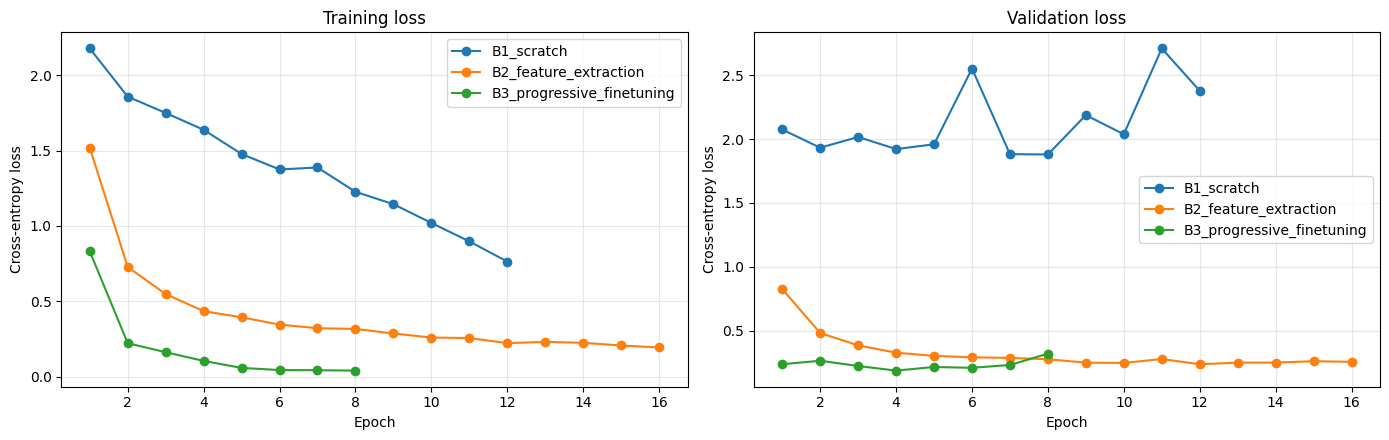

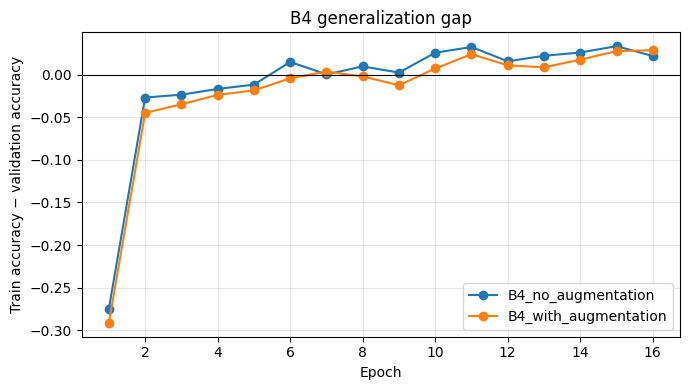

In [8]:
summary = (
    pd.DataFrame(results.values()).sort_values("experiment").reset_index(drop=True)
)
summary.to_csv(ARTIFACT_DIR / "experiment_summary.csv", index=False)
with open(ARTIFACT_DIR / "experiment_summary.json", "w") as f:
    json.dump(summary.to_dict(orient="records"), f, indent=2)
display(
    summary[
        [
            "experiment",
            "trainable_parameters",
            "learning_rates",
            "epochs_ran",
            "best_epoch",
            "duration_seconds",
            "validation_accuracy",
            "test_macro_f1",
            "generalization_gap_pp",
        ]
    ].style.format(
        {
            "duration_seconds": "{:.1f}",
            "validation_accuracy": "{:.4f}",
            "test_macro_f1": "{:.4f}",
            "generalization_gap_pp": "{:.2f}",
        }
    )
)
print("Raw logs:", ARTIFACT_DIR.resolve())

# Kurva B1--B3 yang diperlukan untuk perbandingan pembelajaran.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in ["B1_scratch", "B2_feature_extraction", "B3_progressive_finetuning"]:
    h = pd.DataFrame(histories[name])
    axes[0].plot(h.epoch, h.train_loss, marker="o", label=name)
    axes[1].plot(h.epoch, h.val_loss, marker="o", label=name)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "loss_curves_b1_b2_b3.png", dpi=180, bbox_inches="tight")
plt.show()

# Gap lebih kecil pada B4 adalah indikasi overfitting yang lebih rendah, bukan bukti kausal tunggal.
fig, ax = plt.subplots(figsize=(7, 4))
for name in ["B4_no_augmentation", "B4_with_augmentation"]:
    h = pd.DataFrame(histories[name])
    ax.plot(h.epoch, h.train_accuracy - h.val_accuracy, marker="o", label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set(
    title="B4 generalization gap",
    xlabel="Epoch",
    ylabel="Train accuracy − validation accuracy",
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "b4_generalization_gap.png", dpi=180, bbox_inches="tight")
plt.show()
